# Part 2: Choosing a warehouse robot (Multi-Criteria Decision Analysis)

SweetAroma wants to automate its warehouse and has **7 robot prototypes** (Alpha to Gamma), each scored on 7 criteria.
Two groups have different priorities:

- **Management** wants a robot for scaling up the warehouse. Carrying capacity matters most, then cost.
- **Technical team** cares most about battery, cost and reliability.

I use a **weighted scoring model** (simple additive weighting) to rank the robots for each group,
then a **sensitivity analysis** to check how stable the recommendation is if the weights change.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Load the robot data

In [2]:
robot = pd.read_csv("../data/Robot_Info.csv")

# the file has criteria as rows, so flip it to have one row per robot
robot_df = robot.set_index("Robot_Prototype").T
robot_df = robot_df.astype(float)
robot_df

Robot_Prototype,Carrying Capacity,Battery Size,Speed,Mobility,Aesthetic,Cost Per Unit,Reliability
Alpha,35.000,11.000,15.000,5.000,10.000,10000.000,15.000
Bravo,50.000,6.000,15.000,4.000,6.000,4500.000,24.000
Charlie,50.000,9.000,15.000,3.000,6.000,6250.000,24.000
Delta,40.000,12.000,25.000,4.000,3.000,8000.000,33.000
Echo,55.000,10.000,15.000,2.000,6.000,5500.000,30.000
Foxtrot,70.000,9.000,15.000,1.000,7.000,7500.000,30.000
Gamma,55.000,10.000,18.000,3.000,9.000,5000.000,35.000


**Management priorities** (from `Management_Priority.xlsx`):
- Carrying capacity is the most important, cost is second
- Battery is more important than reliability but less important than mobility
- Speed is as important as mobility (mobility rated 6/10)
- Reliability is slightly more important than aesthetic, and aesthetic is least important

Cost is a **cost criterion** (lower is better). All other criteria are **benefit criteria** (higher is better).

## 2. Normalise the criteria to a 0 to 1 scale

In [3]:
benefit_cols = ["Carrying Capacity", "Battery Size", "Speed", "Mobility", "Aesthetic", "Reliability"]
cost_cols = ["Cost Per Unit"]

def minmax(s):
    # higher is better
    return (s - s.min()) / (s.max() - s.min())

def minmax_cost(s):
    # lower is better, so flip it
    return (s.max() - s) / (s.max() - s.min())

robot_norm = robot_df.copy()
for col in benefit_cols:
    robot_norm[col] = minmax(robot_df[col])
for col in cost_cols:
    robot_norm[col] = minmax_cost(robot_df[col])

robot_norm

Robot_Prototype,Carrying Capacity,Battery Size,Speed,Mobility,Aesthetic,Cost Per Unit,Reliability
Alpha,0.000,0.833,0.000,1.000,1.000,0.000,0.000
Bravo,0.429,0.000,0.000,0.750,0.429,1.000,0.450
Charlie,0.429,0.500,0.000,0.500,0.429,0.682,0.450
Delta,0.143,1.000,1.000,0.750,0.000,0.364,0.900
Echo,0.571,0.667,0.000,0.250,0.429,0.818,0.750
Foxtrot,1.000,0.500,0.000,0.000,0.571,0.455,0.750
Gamma,0.571,0.667,0.300,0.500,0.857,0.909,1.000


## 3. Set the weights
The management weights follow the priority order above. The technical weights put most of the weight on battery, cost and reliability.
Both sets add up to 1.

In [4]:
weights_mgmt = {
    "Carrying Capacity": 0.25, "Cost Per Unit": 0.20, "Mobility": 0.15, "Speed": 0.15,
    "Battery Size": 0.12, "Reliability": 0.08, "Aesthetic": 0.05,
}
weights_tech = {
    "Battery Size": 0.30, "Cost Per Unit": 0.30, "Reliability": 0.25,
    "Carrying Capacity": 0.05, "Speed": 0.05, "Mobility": 0.03, "Aesthetic": 0.02,
}
print("Management weights sum:", round(sum(weights_mgmt.values()), 2))
print("Technical weights sum:", round(sum(weights_tech.values()), 2))

pd.DataFrame({"Management": weights_mgmt, "Technical": weights_tech})

Management weights sum: 1.0
Technical weights sum: 1.0


,Management,Technical
Carrying Capacity,0.250,0.050
Cost Per Unit,0.200,0.300
Mobility,0.150,0.030
Speed,0.150,0.050
Battery Size,0.120,0.300
Reliability,0.080,0.250
Aesthetic,0.050,0.020


## 4. Score and rank the robots

In [5]:
def weighted_score(norm_df, weights):
    w = pd.Series(weights)
    return (norm_df[w.index] * w).sum(axis=1)

scores = pd.DataFrame({
    "Management score": weighted_score(robot_norm, weights_mgmt),
    "Technical score": weighted_score(robot_norm, weights_tech),
})
scores["Management rank"] = scores["Management score"].rank(ascending=False).astype(int)
scores["Technical rank"] = scores["Technical score"].rank(ascending=False).astype(int)
scores.sort_values("Management score", ascending=False)

,Management score,Technical score,Management rank,Technical rank
Gamma,0.648,0.798,1,1
Delta,0.563,0.714,2,2
Echo,0.505,0.678,3,3
Foxtrot,0.489,0.535,4,4
Bravo,0.477,0.465,5,6
Charlie,0.436,0.512,6,5
Alpha,0.300,0.300,7,7


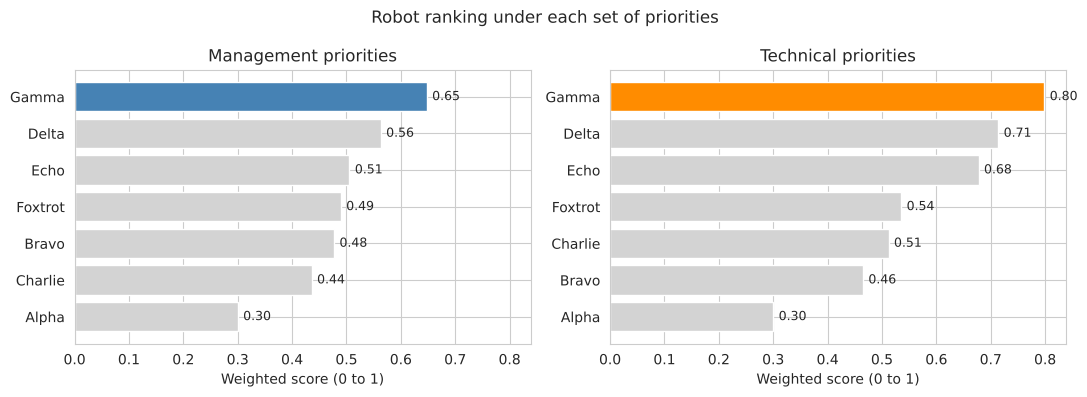

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, col, colour in zip(axes, ["Management score", "Technical score"], ["steelblue", "darkorange"]):
    s = scores[col].sort_values()
    bars = ax.barh(s.index, s.values, color=["lightgrey"] * (len(s) - 1) + [colour])
    ax.set_title(col.replace(" score", " priorities"))
    ax.set_xlabel("Weighted score (0 to 1)")
    for b, v in zip(bars, s.values):
        ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9)
plt.suptitle("Robot ranking under each set of priorities")
plt.tight_layout()
plt.savefig("../images/07_robot_ranking.png", dpi=150)
plt.show()

**Gamma ranks first for both groups.** Delta is second for both.
Because only one robot can be bought for each use, I recommend **Gamma for warehouse scaling (management)** and **Delta as the technical team's choice**, since it is their next-best option.

## 5. Why does Gamma win? Contribution of each criterion

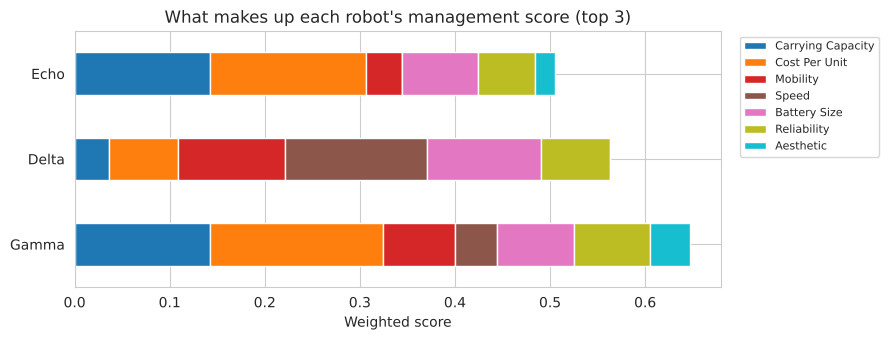

Robot_Prototype,Carrying Capacity,Cost Per Unit,Mobility,Speed,Battery Size,Reliability,Aesthetic
Gamma,0.143,0.182,0.075,0.045,0.080,0.080,0.043
Delta,0.036,0.073,0.112,0.150,0.120,0.072,0.000
Echo,0.143,0.164,0.038,0.000,0.080,0.060,0.021


In [7]:
def contribution_table(norm_df, weights):
    w = pd.Series(weights)
    return norm_df[w.index] * w

contrib = contribution_table(robot_norm, weights_mgmt).loc[["Gamma", "Delta", "Echo"]]

contrib.plot(kind="barh", stacked=True, figsize=(9, 3.5), colormap="tab10")
plt.title("What makes up each robot's management score (top 3)")
plt.xlabel("Weighted score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("../images/08_score_contribution.png", dpi=150)
plt.show()

contrib.round(3)

Gamma does not win by being the best at one thing. It is good on almost everything: high carrying capacity, low cost,
the best reliability and good speed. Delta is strong on speed and battery but loses points on cost and carrying capacity.

## 6. Sensitivity analysis: how stable is the recommendation?
Weights are a judgement, so I check what happens if one weight changes by up to ±15 percentage points.
When one weight goes up, the other weights are reduced in proportion so the total stays at 1.

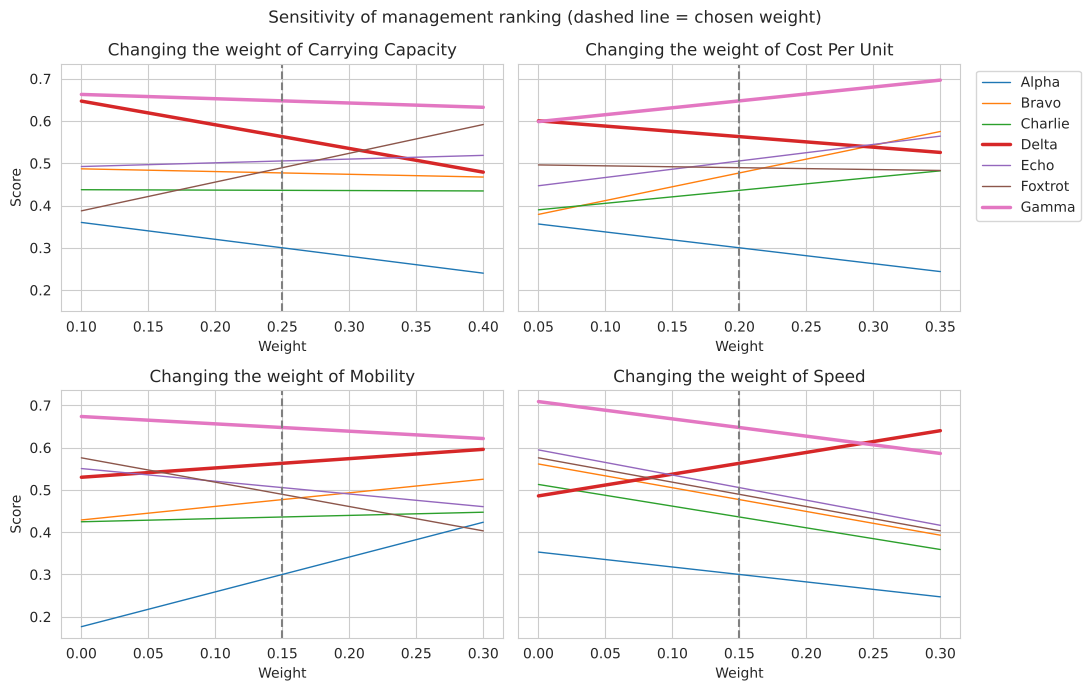

In [8]:
def one_way_sensitivity(norm_df, base_weights, criterion, variation_range=(-0.15, 0.15), steps=21):
    rows = []
    others = [c for c in base_weights if c != criterion]
    other_total = sum(base_weights[c] for c in others)

    for change in np.linspace(variation_range[0], variation_range[1], steps):
        new_w = base_weights[criterion] + change
        if new_w < 0 or new_w > 1:
            continue
        weights = {criterion: new_w}
        for c in others:
            # share the rest of the weight in the same proportions as before
            weights[c] = base_weights[c] / other_total * (1 - new_w)
        s = weighted_score(norm_df, weights)
        row = s.to_dict()
        row["weight"] = new_w
        row["winner"] = s.idxmax()
        rows.append(row)
    return pd.DataFrame(rows)

criteria_to_test = ["Carrying Capacity", "Cost Per Unit", "Mobility", "Speed"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, crit in zip(axes.flat, criteria_to_test):
    res = one_way_sensitivity(robot_norm, weights_mgmt, crit)
    for r in robot_norm.index:
        lw = 2.5 if r in ["Gamma", "Delta"] else 1
        ax.plot(res["weight"], res[r], label=r, linewidth=lw)
    ax.axvline(weights_mgmt[crit], color="grey", linestyle="--")
    ax.set_title(f"Changing the weight of {crit}")
    ax.set_xlabel("Weight")
axes[0, 0].set_ylabel("Score")
axes[1, 0].set_ylabel("Score")
axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Sensitivity of management ranking (dashed line = chosen weight)")
plt.tight_layout()
plt.savefig("../images/09_sensitivity_analysis.png", dpi=150)
plt.show()

In [9]:
# which robot wins at each weight, for every criterion, for both groups
summary = []
for name, base in [("Management", weights_mgmt), ("Technical", weights_tech)]:
    for crit in base:
        res = one_way_sensitivity(robot_norm, base, crit)
        winners = res["winner"].unique()
        lost = res[res["winner"] != "Gamma"]["weight"]
        if len(lost) == 0:
            switch = "-"
        elif lost.min() > base[crit]:
            switch = f"weight above {lost.min():.2f}"
        else:
            switch = f"weight below {lost.max():.2f}"
        summary.append({
            "Weights": name,
            "Criterion changed (±15pp)": crit,
            "Base weight": base[crit],
            "Winners seen": ", ".join(winners),
            "Gamma always first?": "Yes" if list(winners) == ["Gamma"] else "No",
            "Gamma loses first place when": switch,
        })
summary = pd.DataFrame(summary)
summary

,Weights,Criterion changed (±15pp),Base weight,Winners seen,Gamma always first?,Gamma loses first place when
0,Management,Carrying Capacity,0.250,Gamma,Yes,-
1,Management,Cost Per Unit,0.200,"Delta, Gamma",No,weight below 0.05
2,Management,Mobility,0.150,Gamma,Yes,-
3,Management,Speed,0.150,"Gamma, Delta",No,weight above 0.26
4,Management,Battery Size,0.120,Gamma,Yes,-
5,Management,Reliability,0.080,Gamma,Yes,-
6,Management,Aesthetic,0.050,Gamma,Yes,-
7,Technical,Battery Size,0.300,"Gamma, Delta",No,weight above 0.45
8,Technical,Cost Per Unit,0.300,"Delta, Gamma",No,weight below 0.16
9,Technical,Reliability,0.250,Gamma,Yes,-


In [10]:
stable = (summary["Gamma always first?"] == "Yes").sum()
print(f"Gamma stays first in {stable} of {len(summary)} sensitivity tests")
print(summary[summary["Gamma always first?"] == "No"][["Weights", "Criterion changed (±15pp)", "Base weight", "Gamma loses first place when"]].to_string(index=False))

Gamma stays first in 9 of 14 sensitivity tests
   Weights Criterion changed (±15pp)  Base weight Gamma loses first place when
Management             Cost Per Unit        0.200            weight below 0.05
Management                     Speed        0.150            weight above 0.26
 Technical              Battery Size        0.300            weight above 0.45
 Technical             Cost Per Unit        0.300            weight below 0.16
 Technical                     Speed        0.050            weight above 0.16


## 7. Recommendation

1. **Buy Gamma for warehouse scaling.** It has the highest score under management priorities and also under technical priorities.
   It is the cheapest-but-one robot (£5,000) with high carrying capacity and the best reliability, so it is good value.
2. **Delta is the strongest alternative** for the technical team (best battery and fastest robot), but it costs £3,000 more per unit than Gamma.
3. **The result is fairly robust.** Gamma stays first in 9 of 14 sensitivity tests. The only robot that can overtake it is **Delta**,
   and only if cost becomes much less important or speed/battery become much more important than the stated priorities
   (see the table above for the exact switch points). So the real decision is Gamma vs Delta: if budget is tight, Gamma is clearly better.
4. **Avoid Alpha.** It is the most expensive robot and ranks last for both groups.

**Limitations:** the weights are my interpretation of written priorities. A method such as AHP (pairwise comparisons) with the managers
would make the weights more objective. The scores also ignore things like maintenance cost and delivery time, which are not in the data.